# CoSTA for the surface vessel (ODE): correcting unmodeled drag across maneuvers

The corrective-source idea on an ODE. The **reference** vessel carries a nonlinear drag $\boldsymbol{d}(\boldsymbol\nu)$
that the nominal model omits:

$$\mathbf M\dot{\boldsymbol\nu}+\mathbf C(\boldsymbol\nu)\boldsymbol\nu+\mathbf D(\boldsymbol\nu)\boldsymbol\nu
=\boldsymbol\tau+\boldsymbol{d}(\boldsymbol\nu),\qquad \dot{\boldsymbol\eta}=\mathbf R(\psi)\boldsymbol\nu .$$

The **physics-based model (PBM)** is the same equation without $\boldsymbol{d}$. **CoSTA** keeps the PBM and its RK4
integrator and adds a learned force $\boldsymbol{f}_{\boldsymbol{\theta}}(\boldsymbol\nu)$ to the right-hand side. A purely
**data-driven model (DDM)** learns the whole acceleration instead. The heat-equation notebook is the complete worked
protocol; this notebook applies the same protocol to a nonlinear ODE and asks a sharper question:
**does a correction learned on some maneuvers transfer to other maneuvers, and how does it compare with a black box
trained on the same data?**

The chain is the same as for heat:

1. **Partition** whole maneuvers into training, validation and test sets before building any sample.
2. **Build labels** from each reference trajectory, its own recorded controls and the nominal model.
3. **Train** CoSTA and the DDM on the training maneuvers only.
4. **Validate**: at fixed checkpoints run recursive simulations of the validation maneuvers and keep the best checkpoint.
5. **Test**: freeze the models and run recursive simulations of held-out maneuvers. The reference is used only to score.

The prose narrates the **default** run. Change the values below and *Run All*; every figure, table and saved
result follows. Text that quotes the default numbers does not update, so read the printed values when you change
parameters.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0                       # network initialization seed for the walkthrough
T_END, DT = 30.0, 0.02         # horizon [s] and RK4 step [s] of every maneuver
DRAG = [3.0, 8.0, 2.0]         # hidden drag d = -[c_u u|u|, c_v v|v|, c_r r|r|]  (reference only)
# maneuvers: (kind, surge thrust [N], yaw moment [N m], switch heading [rad]); all start at rest, z0 = 0
#   TC = turning circle (constant controls);  ZZ = zig-zag (yaw moment flips when psi crosses -/+ switch)
TRAIN = [('TC', 120, 30, 0.0), ('TC', 120, -30, 0.0), ('TC', 80, 50, 0.0),
         ('ZZ', 130, 75, 0.35), ('ZZ', 90, 55, 0.5)]
VAL = [('TC', 100, 40, 0.0), ('ZZ', 100, 70, 0.5)]                 # checkpoint / filter selection only
TEST_INTERP = [('TC', 110, -40, 0.0), ('ZZ', 110, 65, 0.4)]        # held out, states inside the training box
TEST_EXTRAP = [('ZZ', 160, 80, 0.35), ('TC', 300, -25, 0.0)]       # held out, states leave the training box
RECON = ('TC', 120, 30, 0.0)   # the original turning circle: a TRAINING reconstruction diagnostic
SHOW_INTERP = ('ZZ', 110, 65, 0.4)   # test case drawn in the correction and alpha figures
SHOW_EXTRAP = ('ZZ', 160, 80, 0.35)  # test case drawn in the generalization and time-series figures
COSTA_HIDDEN, DDM_HIDDEN = [32, 32], [64, 64]
LR = 2e-3                      # Adam; learning rate halves every 2000 steps
COSTA_MAX_STEPS, DDM_MAX_STEPS = 3000, 4000
VAL_EVERY = 250                # validation interval [steps]
PATIENCE = 6                   # stop after this many validations without improvement
MIN_REL_IMPROVEMENT = 0.01     # an improvement must beat the best by 1 %
NU_FLOOR, TAU_FLOOR = 0.1, 10.0  # DDM input-scale floors [m/s or rad/s], [N or N m]
NOISE_STD = 0.004              # velocity measurement noise (std) for the noise experiment
NOISE_SEED_BASE = 1000         # noise seeds 1000, 1001, ... (separate from network seeds)
WINDOWS = [1, 11, 21, 41, 81]  # candidate moving-average windows [samples], chosen on validation
ALPHAS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
RUN_SEED_SWEEP = False         # True retrains CoSTA and DDM for SWEEP_SEEDS (~2 min) and saves the table
SWEEP_SEEDS = [0, 1, 2, 3, 4]
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, T_END=30.0, DT=0.02, DRAG=[3.0, 8.0, 2.0],
                TRAIN=[('TC', 120, 30, 0.0), ('TC', 120, -30, 0.0), ('TC', 80, 50, 0.0),
                       ('ZZ', 130, 75, 0.35), ('ZZ', 90, 55, 0.5)],
                VAL=[('TC', 100, 40, 0.0), ('ZZ', 100, 70, 0.5)],
                TEST_INTERP=[('TC', 110, -40, 0.0), ('ZZ', 110, 65, 0.4)],
                TEST_EXTRAP=[('ZZ', 160, 80, 0.35), ('TC', 300, -25, 0.0)],
                COSTA_HIDDEN=[32, 32], DDM_HIDDEN=[64, 64], LR=2e-3, COSTA_MAX_STEPS=3000,
                DDM_MAX_STEPS=4000, VAL_EVERY=250, PATIENCE=6, MIN_REL_IMPROVEMENT=0.01,
                NU_FLOOR=0.1, TAU_FLOOR=10.0, NOISE_STD=0.004, NOISE_SEED_BASE=1000,
                WINDOWS=[1, 11, 21, 41, 81])
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

### Setup: the reference vessel, the nominal PBM and one RK4 integrator for every model

The state is $\boldsymbol{z}=[\boldsymbol\eta,\boldsymbol\nu]=[x,y,\psi,u,v,r]$ with
$\mathbf M=\mathrm{diag}(55,80,30)$ (rigid body plus added mass), the Coriolis matrix $\mathbf C(\boldsymbol\nu)$ and
damping $\mathbf D(\boldsymbol\nu)$ of the course vessel benchmark (`pyutils.benchmarks.vessel`). The reference adds
the hidden drag $\boldsymbol{d}(\boldsymbol\nu)=[-3u|u|,\,-8v|v|,\,-2r|r|]^\top$.

All models share one integrator, `rk4_step`: classical RK4 with the control $\boldsymbol\tau_k$ held constant over
the step, and the kinematics $\dot{\boldsymbol\eta}=\mathbf R(\psi)\boldsymbol\nu$ integrated together with the
velocities. The models differ **only** in the acceleration they supply:

| model | acceleration $\dot{\boldsymbol\nu}$ |
|---|---|
| reference | $\mathbf M^{-1}\left(\boldsymbol\tau-\mathbf C\boldsymbol\nu-\mathbf D\boldsymbol\nu+\boldsymbol{d}(\boldsymbol\nu)\right)$ |
| PBM | $\mathbf M^{-1}\left(\boldsymbol\tau-\mathbf C\boldsymbol\nu-\mathbf D\boldsymbol\nu\right)$ |
| CoSTA | $\mathbf M^{-1}\left(\boldsymbol\tau-\mathbf C\boldsymbol\nu-\mathbf D\boldsymbol\nu+\alpha\,\boldsymbol{f}_{\boldsymbol{\theta}}(\boldsymbol\nu)\right)$, with $\alpha=1$ unless stated |
| DDM | $\boldsymbol{g}_\phi(\boldsymbol\nu,\boldsymbol\tau)$, a black box |

The functions below are vectorized over maneuvers so that several rollouts run at once. A check confirms that the
nominal right-hand side equals the shared benchmark's `state_derivative`.

In [2]:
import sys, os, copy, json, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP
from pyutils import save_dual, fg, muted
from pyutils.benchmarks import vessel
torch.set_default_dtype(torch.float64)
pc.set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
DATA = os.path.abspath(os.path.join('..', 'data')); os.makedirs(DATA, exist_ok=True)
RESULTS_FILE = os.path.join(DATA, 'costa_vessel_results.json')
T_START = time.time()

p = vessel.VesselParams(); M = p.M(); M_DIAG = np.diag(M).copy()
assert np.allclose(M, np.diag(M_DIAG)), 'the vectorized code assumes a diagonal mass matrix'
M11, M22 = p.m - p.X_udot, p.m - p.Y_vdot
N_STEPS = int(round(T_END / DT)); t_grid = np.arange(N_STEPS + 1)*DT
DRAG_C = np.array(DRAG, float)

def drag(nu):
    """The hidden drag d(nu): used by the reference only (and for scoring the learned force)."""
    return -DRAG_C*nu*np.abs(nu)

def nominal_force(nu):
    """C(nu) nu + D(nu) nu of the PBM, vectorized over leading axes."""
    u, v, r = nu[..., 0], nu[..., 1], nu[..., 2]
    Cnu = np.stack([-M22*v*r, M11*u*r, (M22 - M11)*u*v], -1)
    Dnu = np.stack([(p.Du + p.Xuu*np.abs(u))*u, (p.Dv + p.Yvv*np.abs(v))*v, (p.Dr + p.Nrr*np.abs(r))*r], -1)
    return Cnu + Dnu

def kinematics(z):
    psi, u, v, r = z[..., 2], z[..., 3], z[..., 4], z[..., 5]
    c, s = np.cos(psi), np.sin(psi)
    return np.stack([c*u - s*v, s*u + c*v, r], -1)

def rk4_step(z, tau, accel):
    """One RK4 step of eta_dot = R(psi) nu, nu_dot = accel(nu, tau), with tau held over the step."""
    rhs = lambda zz: np.concatenate([kinematics(zz), accel(zz[..., 3:], tau)], -1)
    k1 = rhs(z); k2 = rhs(z + 0.5*DT*k1); k3 = rhs(z + 0.5*DT*k2); k4 = rhs(z + DT*k3)
    return z + DT/6*(k1 + 2*k2 + 2*k3 + k4)

def accel_pbm(nu, tau, extra=None):
    f = tau - nominal_force(nu)
    if extra is not None:
        f = f + extra
    return f / M_DIAG

def accel_ref(nu, tau):
    return accel_pbm(nu, tau, drag(nu))

zr = np.random.default_rng(0).normal(size=6); tr_ = np.array([100.0, 0.0, 30.0])
assert np.allclose(np.concatenate([kinematics(zr), accel_pbm(zr[3:], tr_)]), vessel.state_derivative(zr, tr_, p))
print(f'M = diag{tuple(M_DIAG)}, {N_STEPS} RK4 steps of {DT} s to T = {T_END} s')
print('nominal right-hand side matches vessel.state_derivative')

M = diag(55.0, 80.0, 30.0), 1500 RK4 steps of 0.02 s to T = 30.0 s
nominal right-hand side matches vessel.state_derivative


## 1. Maneuvers, and partitioning them before anything is learned

A **case** is one complete maneuver: its control law, initial state (rest) and horizon (30 s). Two kinds are used.

* **Turning circle** `TC(thrust, yaw)`: constant surge thrust and yaw moment.
* **Zig-zag** `ZZ(thrust, yaw, switch)`: the yaw moment is $\pm$yaw, and it flips sign when the heading crosses the
  *opposite* switch line $\mp\psi_s$. This is the hysteretic law `vessel.zigzag(..., hysteresis=True)`; its memory is
  reset at $t=0$ of every run.

The reference is simulated with its control law in the loop. The control applied at every step is **recorded**,
and that log is what every later step uses: the labels use each maneuver's own controls, and every model rollout
replays the recorded controls. So all models are compared on the same prescribed input sequence. This measures
**prediction** error, not closed-loop performance: a model does not run its own autopilot.

This hull is directionally unstable at these speeds, so a small yaw moment produces a tight turn and a weak
zig-zag command never turns the vessel back. We print the number of command switches and the heading range of
every zig-zag to verify that each one really alternates.

In [3]:
ROLES = ['train', 'val', 'test_interp', 'test_extrap']
SPLIT = {'train': TRAIN, 'val': VAL, 'test_interp': TEST_INTERP, 'test_extrap': TEST_EXTRAP}
ROLE_LABEL = {'train': 'training', 'val': 'validation', 'test_interp': 'test (interpolation)',
              'test_extrap': 'test (extrapolation)'}
ROLE_COLOR = {'train': 'C0', 'val': 'C4', 'test_interp': 'C2', 'test_extrap': 'C3'}

def name(m):
    kind, surge, yaw, psw = m
    return f'TC({surge:g}, {yaw:+g})' if kind == 'TC' else f'ZZ({surge:g}, ±{abs(yaw):g}, {psw:g})'

all_cases = [m for role in ROLES for m in SPLIT[role]]
assert len(set(all_cases)) == len(all_cases), 'a maneuver appears in two roles'
assert RECON in TRAIN and SHOW_INTERP in TEST_INTERP and SHOW_EXTRAP in TEST_EXTRAP
assert any(m[2] > 0 for m in TRAIN) and any(m[2] < 0 for m in TRAIN), 'train on both yaw directions'

def simulate_reference(m):
    """Reference run with the control law in the loop; returns states (N+1, 6) and recorded controls (N, 3)."""
    kind, surge, yaw, psw = m
    law = vessel.turning_circle(surge, yaw) if kind == 'TC' else vessel.zigzag(surge, yaw, psw, hysteresis=True)
    z = np.zeros(6); Z = [z]; TAU = []
    for k in range(N_STEPS):
        tau = np.asarray(law(k*DT, z), float); TAU.append(tau)
        z = rk4_step(z, tau, accel_ref); Z.append(z)
    return np.array(Z), np.array(TAU)

CASES = {}
for role in ROLES:
    for m in SPLIT[role]:
        Z, TAU = simulate_reference(m)
        CASES[m] = dict(role=role, Z=Z, tau=TAU)
MANIFEST = {role: [dict(case=name(m), kind=m[0], surge_N=m[1], yaw_Nm=m[2], psi_switch_rad=m[3],
                        z0=[0.0]*6, horizon_s=T_END, dt_s=DT, integrator='RK4, control held over the step')
                   for m in SPLIT[role]] for role in ROLES}

# recorded controls reproduce the reference exactly when replayed (the rollouts below rely on this)
def replay(cases, accel):
    TAU = np.stack([CASES[m]['tau'] for m in cases]); z = np.zeros((len(cases), 6)); out = [z]
    with np.errstate(all='ignore'):
        for k in range(N_STEPS):
            z = rk4_step(z, TAU[:, k], accel); out.append(z)
    return np.stack(out, 1)
assert np.array_equal(replay([RECON], accel_ref)[0], CASES[RECON]['Z'])

print(f"{'role':12s} {'maneuver':20s} {'switches':>8s} {'psi range [deg]':>17s}")
for m in all_cases:
    c = CASES[m]; nsw = int((np.diff(c['tau'][:, 2]) != 0).sum())
    psi = np.degrees(c['Z'][:, 2])
    print(f"{c['role']:12s} {name(m):20s} {nsw:8d} {psi.min():8.0f} {psi.max():8.0f}")
    if m[0] == 'ZZ':
        assert nsw >= 4, f'{name(m)} does not zig-zag'

role         maneuver             switches   psi range [deg]
train        TC(120, +30)                0        0     2505
train        TC(120, -30)                0    -2505        0
train        TC(80, +50)                 0        0     2737
train        ZZ(130, ±75, 0.35)         13      -84       78
train        ZZ(90, ±55, 0.5)           11      -84       79
val          TC(100, +40)                0        0     2595
val          ZZ(100, ±70, 0.5)          13      -81       78
test_interp  TC(110, -40)                0    -2657        0
test_interp  ZZ(110, ±65, 0.4)          12      -83       78
test_extrap  ZZ(160, ±80, 0.35)         13     -100       84
test_extrap  TC(300, -25)                0    -3549        0


Every zig-zag switches its command 11 to 13 times in 30 s and keeps its heading between $-100^\circ$ and
$+84^\circ$, so the maneuvers are genuine zig-zags. The turning circles never switch. They wind up $2500^\circ$
to $3550^\circ$ of heading, seven to ten full turns in 30 s.

**Why these splits.** The roles were fixed from state coverage alone, before any model was trained:

* Training uses three turning circles (both yaw directions, two thrusts) and two zig-zags.
* Validation and the interpolation tests use new thrust and yaw values that lie between training values.
* The extrapolation tests use higher thrust: a strong zig-zag at 160 N, and a turning circle at 300 N.

The network does not see the maneuver parameters. CoSTA sees the velocity $(u,v,r)$; the DDM sees $(u,v,r)$ and the
control $\boldsymbol\tau$. So the meaningful question is whether a test maneuver's **states** (and, for the DDM,
its **controls**) lie inside what the training maneuvers visited. The next cell measures this with the smallest box
containing all training velocities.

In [4]:
NU_TRAIN = np.vstack([CASES[m]['Z'][:, 3:] for m in TRAIN])
BOX_LO, BOX_HI = NU_TRAIN.min(0), NU_TRAIN.max(0)
TAU_TRAIN = np.vstack([CASES[m]['tau'] for m in TRAIN])
TAU_LO, TAU_HI = TAU_TRAIN.min(0), TAU_TRAIN.max(0)
COVERAGE = {}
print('training box: u [{:.2f}, {:.2f}] m/s, v [{:.2f}, {:.2f}] m/s, r [{:.2f}, {:.2f}] rad/s'.format(
      *np.ravel(np.column_stack([BOX_LO, BOX_HI]))))
print(f"{'role':12s} {'maneuver':20s} {'states outside box':>18s} {'controls inside training range':>31s}")
for m in all_cases:
    nu = CASES[m]['Z'][:, 3:]; tau = CASES[m]['tau']
    frac = float(((nu < BOX_LO - 1e-12) | (nu > BOX_HI + 1e-12)).any(1).mean())
    ctrl_in = bool(np.all((tau >= TAU_LO) & (tau <= TAU_HI)))
    COVERAGE[name(m)] = dict(role=CASES[m]['role'], frac_states_outside_box=frac, controls_in_training_range=ctrl_in)
    print(f"{CASES[m]['role']:12s} {name(m):20s} {frac:18.2f} {str(ctrl_in):>31s}")
for m in TEST_INTERP + VAL:
    assert COVERAGE[name(m)]['frac_states_outside_box'] == 0.0, f'{name(m)} is not an interpolation case'
for m in TEST_EXTRAP:
    assert COVERAGE[name(m)]['frac_states_outside_box'] > 0.2, f'{name(m)} barely leaves the training box'

training box: u [0.00, 3.03] m/s, v [-1.60, 1.51] m/s, r [-2.45, 2.56] rad/s
role         maneuver             states outside box  controls inside training range
train        TC(120, +30)                       0.00                            True
train        TC(120, -30)                       0.00                            True
train        TC(80, +50)                        0.00                            True
train        ZZ(130, ±75, 0.35)                 0.00                            True
train        ZZ(90, ±55, 0.5)                   0.00                            True
val          TC(100, +40)                       0.00                            True
val          ZZ(100, ±70, 0.5)                  0.00                            True
test_interp  TC(110, -40)                       0.00                            True
test_interp  ZZ(110, ±65, 0.4)                  0.00                            True
test_extrap  ZZ(160, ±80, 0.35)                 0.29                     

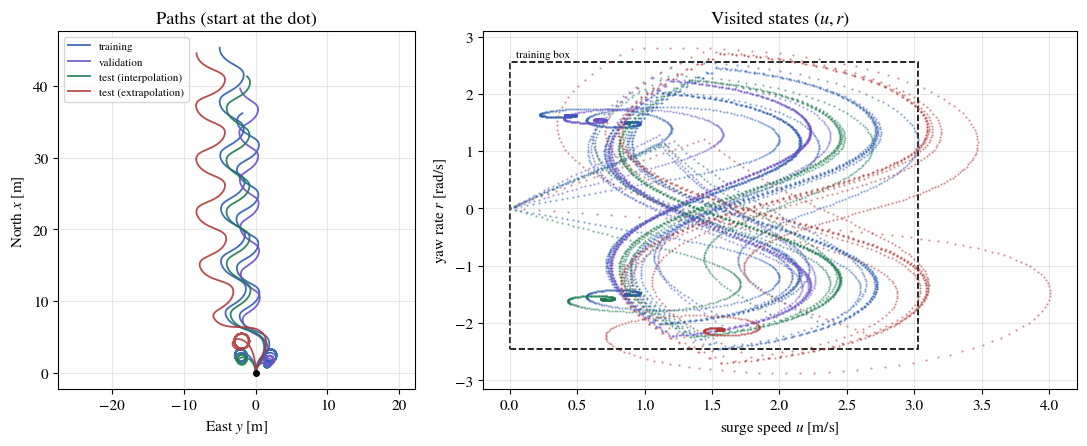

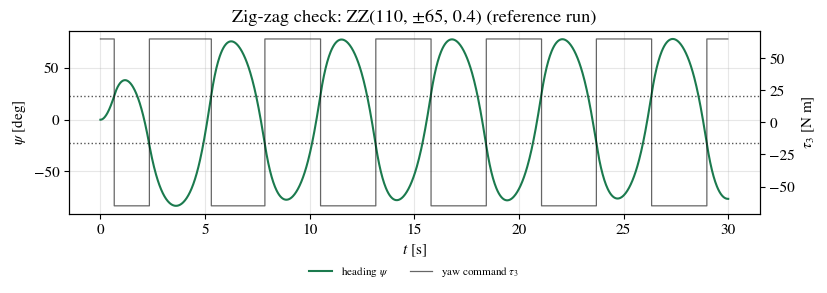

In [5]:
def plot_costa_vessel_split():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw=dict(width_ratios=[0.75, 1.25]))
    seen = set()
    for m in all_cases:
        role = CASES[m]['role']; Z = CASES[m]['Z']
        ax[0].plot(Z[:, 1], Z[:, 0], color=ROLE_COLOR[role], lw=1.3, alpha=0.9,
                   label=None if role in seen else ROLE_LABEL[role]); seen.add(role)
    ax[0].plot(0, 0, 'o', color=fg(), ms=4)
    ax[0].set_aspect('equal', adjustable='datalim')
    ax[0].set(xlabel='East $y$ [m]', ylabel='North $x$ [m]', title='Paths (start at the dot)')
    ax[0].legend(fontsize=8, loc='upper left')
    for role in ROLES:
        for m in SPLIT[role]:
            nu = CASES[m]['Z'][:, 3:]
            ax[1].plot(nu[:, 0], nu[:, 2], '.', ms=1.2, color=ROLE_COLOR[role], alpha=0.5)
    ax[1].add_patch(plt.Rectangle((BOX_LO[0], BOX_LO[2]), BOX_HI[0]-BOX_LO[0], BOX_HI[2]-BOX_LO[2],
                                  fill=False, ls='--', lw=1.2, ec=fg()))
    ax[1].text(BOX_LO[0] + 0.05, BOX_HI[2] + 0.08, 'training box', fontsize=8)
    ax[1].set(xlabel='surge speed $u$ [m/s]', ylabel='yaw rate $r$ [rad/s]', title='Visited states $(u, r)$')
    plt.tight_layout()

save_dual(plot_costa_vessel_split, 'costa_vessel_split', FIG)
plt.show()

zz_show = CASES[SHOW_INTERP]

def plot_costa_vessel_zigzag():
    fig, ax = plt.subplots(figsize=(8.4, 3.2))
    ax.plot(t_grid, np.degrees(zz_show['Z'][:, 2]), color='C2', label=r'heading $\psi$')
    psw = np.degrees(SHOW_INTERP[3])
    for s in (-1, 1):
        ax.axhline(s*psw, color=muted(), ls=':', lw=1)
    ax.set(xlabel='$t$ [s]', ylabel=r'$\psi$ [deg]', title=f'Zig-zag check: {name(SHOW_INTERP)} (reference run)')
    ax2 = ax.twinx()
    ax2.step(t_grid[:-1], zz_show['tau'][:, 2], where='post', color=fg(), lw=0.9, alpha=0.6, label=r'yaw command $\tau_3$')
    ax2.set_ylabel(r'$\tau_3$ [N m]'); ax2.grid(False)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
    plt.tight_layout()

save_dual(plot_costa_vessel_zigzag, 'costa_vessel_zigzag', FIG)
plt.show()

Left: the zig-zags travel 30 to 45 m north while weaving, and the turning circles stay within a few metres of
the start because this hull turns tightly. Right: the velocity states in the $(u,r)$ plane, with the training box
dashed. Validation and interpolation states fall inside it. The 160 N zig-zag reaches higher surge and yaw rates,
and the 300 N turning circle settles at a sway speed $v\approx1.57$ m/s, just above the training maximum of 1.51 m/s.
(In the $(u,r)$ projection it looks inside the box; it leaves the box in $v$.) These are the extrapolation cases,
with 0.29 and 0.94 of their states outside the box. The second figure confirms that the heading of the
displayed zig-zag reverses each time it crosses the opposite switch line.

The box is a coarse summary. A state inside it may still be far from any training state, since the training
trajectories are curves in a three-dimensional space. Every control in the interpolation tests lies inside the
training control range; the extrapolation tests use more thrust (and, for the zig-zag, a larger yaw moment) than
any training maneuver. That matters for the DDM, whose input includes the control.

## 2. Labels from each trajectory and its own controls

For a sample at time $t_k$ of one maneuver, the **acceleration estimate** is the central difference
$\hat{\dot{\boldsymbol\nu}}_k=(\boldsymbol\nu_{k+1}-\boldsymbol\nu_{k-1})/(2\Delta t)$ of the logged velocities.
Two choices keep this honest:

* it is computed **within** one maneuver, never across maneuvers;
* a sample is dropped when the recorded control changes inside its difference stencil (at a zig-zag switch the
  acceleration jumps and the central difference would mix two controls), and the first and last samples are dropped.

Both models are fitted to the same samples:

* **CoSTA label**, the residual force of the nominal model,
  $\boldsymbol{f}_{\mathrm{ref},k}=\mathbf M\hat{\dot{\boldsymbol\nu}}_k+\mathbf C(\boldsymbol\nu_k)\boldsymbol\nu_k
  +\mathbf D(\boldsymbol\nu_k)\boldsymbol\nu_k-\boldsymbol\tau_k$, with input $\boldsymbol\nu_k$;
* **DDM target**, the acceleration $\hat{\dot{\boldsymbol\nu}}_k$ itself, with input $[\boldsymbol\nu_k,\boldsymbol\tau_k]$.

The label uses the reference at $t_{k+1}$, which is available when building the training set and **not** at
prediction time. In a rollout the network sees only the model's own current velocity.

CoSTA's input is the velocity alone. That is a modelling assumption, and it is valid here because the synthetic drag
depends only on $\boldsymbol\nu$. An environmental force that depends on time, position or heading (a current fixed
in the Earth frame, wind, waves) would need those quantities, or measurements of them, as extra inputs; without them
the force is not a function of the network's input and cannot be learned.

In [6]:
def moving_average(x, w):
    """Centered moving average along time; NaN where the window is incomplete (no edge padding)."""
    if w == 1:
        return x.copy()
    out = np.full_like(x, np.nan); h = w//2; ker = np.ones(w)/w
    for j in range(x.shape[1]):
        out[h:len(x)-h, j] = np.convolve(x[:, j], ker, 'valid')
    return out

def samples(m, window=1, nu_obs=None):
    """Samples (nu_k, tau_k, nu_dot_k) of ONE maneuver, using its own recorded controls."""
    nu = CASES[m]['Z'][:, 3:] if nu_obs is None else nu_obs
    tau = CASES[m]['tau']; h = window//2
    nus = moving_average(nu, window)
    nd = np.full_like(nus, np.nan); nd[1:-1] = (nus[2:] - nus[:-2])/(2*DT)
    # keep k only if the window behind nus[k-1], nus[k+1] covers one constant control
    keep = [k for k in range(h + 1, N_STEPS - h) if np.all(tau[k-1-h:k+h+1] == tau[k])]
    return nus[keep], tau[keep], nd[keep]

def dataset(cases, window=1, obs=None):
    parts = [samples(m, window, None if obs is None else obs[m]) for m in cases]
    return [np.vstack([q[j] for q in parts]) for j in range(3)]

def residual_force(nu, tau, nu_dot):
    return nu_dot*M_DIAG + nominal_force(nu) - tau

NU_tr, TAU_tr, ND_tr = dataset(TRAIN); F_tr = residual_force(NU_tr, TAU_tr, ND_tr)
NU_va, TAU_va, ND_va = dataset(VAL); F_va = residual_force(NU_va, TAU_va, ND_va)
lab_err = np.sqrt(np.mean((F_tr - drag(NU_tr))**2, 0)); lab_max = np.abs(F_tr - drag(NU_tr)).max(0)
n_switch = sum(int((np.diff(CASES[m]['tau'][:, 2]) != 0).sum()) for m in TRAIN)
print(f'training samples: {len(NU_tr)} from {len(TRAIN)} maneuvers ({N_STEPS - 1} interior samples each; '
      f'{len(TRAIN)*(N_STEPS - 1) - len(NU_tr)} dropped at {n_switch} control switches);  validation samples: {len(NU_va)}')
print('label error vs the true drag on training samples (RMS, N or N m):', np.round(lab_err, 3),
      '  max:', np.round(lab_max, 2))
# what the same central difference does if it is allowed to straddle the switches
nd_all = np.vstack([np.gradient(CASES[m]['Z'][:, 3:], DT, axis=0)[:-1] for m in TRAIN])
nu_all = np.vstack([CASES[m]['Z'][:-1, 3:] for m in TRAIN]); tau_all = np.vstack([CASES[m]['tau'] for m in TRAIN])
print('for comparison, np.gradient across the switches: max label error',
      np.round(np.abs(residual_force(nu_all, tau_all, nd_all) - drag(nu_all)).max(0), 1))
print(f'size of the true drag on training samples (RMS): {np.round(np.sqrt(np.mean(drag(NU_tr)**2, 0)), 2)}')

training samples: 7471 from 5 maneuvers (1499 interior samples each; 24 dropped at 24 control switches);  validation samples: 2985
label error vs the true drag on training samples (RMS, N or N m): [0.021 0.04  0.009]   max: [0.14 0.4  0.09]
for comparison, np.gradient across the switches: max label error [ 3.3  3.1 76.9]
size of the true drag on training samples (RMS): [7.46 6.4  4.5 ]


The labels are close to the true drag: a few hundredths of a newton RMS and at most a few tenths, which is the
truncation error of the central difference. Dropping the samples at control switches matters. A central difference
taken straight across a switch mixes the accelerations before and after the yaw moment flips, and the comparison
line shows label errors of up to 77 N m in yaw at those samples. Dropping them costs one sample per switch (24 of
the 7495 interior training samples); splitting each maneuver into constant-control segments and differencing within each segment is
an equivalent alternative. The same rule is applied when smoothing in Section 8: a smoothing window may not span a
switch, so the filter also works within constant-control segments. Note that we print this comparison only because the example is synthetic. In practice
$\boldsymbol{d}$ is unknown and the label is all there is.

## 3. Training both models, with validation-based checkpoint selection

| | CoSTA | DDM |
|---|---|---|
| network | $\boldsymbol{f}_{\boldsymbol{\theta}}(\boldsymbol\nu)$, MLP $[3,32,32,3]$, tanh | $\boldsymbol{g}_\phi(\boldsymbol\nu,\boldsymbol\tau)$, MLP $[6,64,64,3]$, tanh |
| target | residual force $\boldsymbol{f}_{\mathrm{ref}}$ | acceleration $\hat{\dot{\boldsymbol\nu}}$ |
| physics in the model | $\mathbf M$, $\mathbf C$, $\mathbf D$, kinematics | kinematics only |
| maximum Adam steps | 3000 | 4000 |

Everything else is shared: the training samples, full-batch Adam with learning rate $2\times10^{-3}$ halving
every 2000 steps, standardized MSE, the validation schedule and the RK4 rollout. The DDM is a learned velocity
dynamics with known kinematics; the only thing CoSTA has that the DDM lacks is the nominal physics.

**Normalization** is fitted on training rows only. Each input is centred on its training mean and divided by its
training standard deviation, but never by less than a declared floor (0.1 for velocities, 10 N or N m for controls).
The floor matters for the DDM: the sway control is zero in every maneuver, so its standard deviation is zero, and an
unfloored scale would turn any nonzero value into an enormous input.

**Validation.** Every 250 steps, without updating the weights, we run both validation maneuvers recursively and
record the mean position RMSE. The checkpoint with the lowest value is kept, a non-finite rollout counts as
$+\infty$, and training stops after 6 validations without a 1 % improvement. The selected checkpoint is restored
before testing. The one-step regression MSE on validation reference states is recorded as a diagnostic.

In [7]:
def numpy_weights(net):
    return [(mod.weight.detach().numpy().copy(), mod.bias.detach().numpy().copy())
            for mod in net.net if isinstance(mod, torch.nn.Linear)]

def forward(W, x):
    for i, (A, b) in enumerate(W):
        x = x @ A.T + b
        if i < len(W) - 1:
            x = np.tanh(x)
    return x

class Learned:
    """A trained network plus its training-set normalization; evaluated in numpy for fast rollouts."""
    def __init__(self, kind, net, stats):
        self.kind, self.net, self.stats = kind, net, stats
        self.freeze()
    def freeze(self):
        self.W = numpy_weights(self.net)
    def inputs(self, nu, tau=None):
        Xm, Xs = self.stats[:2]
        X = nu if self.kind == 'costa' else np.concatenate([nu, tau], -1)
        return (X - Xm)/Xs
    def __call__(self, nu, tau=None):
        Ym, Ys = self.stats[2:]
        return forward(self.W, self.inputs(nu, tau))*Ys + Ym

def accel_of(model, alpha=1.0):
    if model is None:
        return lambda nu, tau: accel_pbm(nu, tau)
    if model.kind == 'costa':
        return lambda nu, tau: accel_pbm(nu, tau, alpha*model(nu))
    return lambda nu, tau: model(nu, tau)

def rollout(cases, model=None, alpha=1.0):
    """Recursive simulation from rest with the recorded controls. Never reads the reference states."""
    return replay(cases, accel_of(model, alpha))

def scores(P, Z):
    """Metrics in physical units: position [m], wrapped heading [deg], velocity RMSE per component."""
    if not np.all(np.isfinite(P)):
        inf = float('inf')
        return dict(pos_rmse=inf, pos_final=inf, head_rms_deg=inf, head_final_deg=inf, vel_rmse=[inf]*3)
    e = np.hypot(P[:, 0] - Z[:, 0], P[:, 1] - Z[:, 1])
    dpsi = np.degrees(np.angle(np.exp(1j*(P[:, 2] - Z[:, 2]))))
    return dict(pos_rmse=float(np.sqrt(np.mean(e**2))), pos_final=float(e[-1]),
                head_rms_deg=float(np.sqrt(np.mean(dpsi**2))), head_final_deg=float(abs(dpsi[-1])),
                vel_rmse=[float(v) for v in np.sqrt(np.mean((P[:, 3:] - Z[:, 3:])**2, 0))])

def val_rollout_score(model):
    P = rollout(VAL, model)
    return float(np.mean([scores(P[i], CASES[m]['Z'])['pos_rmse'] for i, m in enumerate(VAL)]))

def fit(kind, seed=SEED, data=None, verbose=False):
    """Train CoSTA ('costa') or the DDM ('ddm') on the training samples; select the checkpoint on validation."""
    NU, TAU, ND = data if data is not None else (NU_tr, TAU_tr, ND_tr)
    if kind == 'costa':
        X, Y = NU, residual_force(NU, TAU, ND); Xv, Yv = NU_va, F_va
        floor, hidden, max_steps = np.full(3, NU_FLOOR), COSTA_HIDDEN, COSTA_MAX_STEPS
    else:
        X, Y = np.hstack([NU, TAU]), ND; Xv, Yv = np.hstack([NU_va, TAU_va]), ND_va
        floor = np.r_[np.full(3, NU_FLOOR), np.full(3, TAU_FLOOR)]
        hidden, max_steps = DDM_HIDDEN, DDM_MAX_STEPS
    Xm, Xs = X.mean(0), np.maximum(X.std(0), floor)        # training rows only
    Ym, Ys = Y.mean(0), Y.std(0)
    Xt, Yt = torch.tensor((X - Xm)/Xs), torch.tensor((Y - Ym)/Ys)
    Xvt, Yvt = torch.tensor((Xv - Xm)/Xs), torch.tensor((Yv - Ym)/Ys)
    torch.manual_seed(seed)
    net = MLP([X.shape[1], *hidden, 3]); model = Learned(kind, net, (Xm, Xs, Ym, Ys))
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2000, gamma=0.5)
    hist = dict(step=[], train_mse=[], val_mse=[], val_rollout=[])
    best, best_step, best_state, waited = np.inf, 0, None, 0
    for k in range(max_steps + 1):
        if k % VAL_EVERY == 0 or k == max_steps:
            model.freeze()
            with torch.no_grad():
                tr = ((net(Xt) - Yt)**2).mean().item(); va = ((net(Xvt) - Yvt)**2).mean().item()
            vr = val_rollout_score(model)
            for key, val in zip(hist, (k, tr, va, vr)):
                hist[key].append(val)
            if vr < best*(1 - MIN_REL_IMPROVEMENT):
                best, best_step, best_state, waited = vr, k, copy.deepcopy(net.state_dict()), 0
            else:
                waited += 1
            if verbose and k % 1000 == 0:
                print(f'  {kind} step {k:5d}  train mse {tr:.2e}  val mse {va:.2e}  val rollout pos RMSE {vr:.3f} m')
            if waited >= PATIENCE or k == max_steps:
                break
        opt.zero_grad(); loss = ((net(Xt) - Yt)**2).mean(); loss.backward(); opt.step(); sched.step()
    if best_state is None:                                 # every validation rollout was non-finite
        best_state = copy.deepcopy(net.state_dict())
    net.load_state_dict(best_state); net.eval(); model.freeze()   # restore the selected checkpoint
    return model, dict(hist=hist, best_step=best_step, best_val_rollout=best, stopped_at=k)

t0 = time.time()
costa, info_c = fit('costa', verbose=True)
print(f"CoSTA: selected step {info_c['best_step']} (validation position RMSE {info_c['best_val_rollout']:.3f} m), "
      f"stopped at {info_c['stopped_at']}, {time.time()-t0:.0f} s")
t0 = time.time()
ddm, info_d = fit('ddm', verbose=True)
print(f"DDM:   selected step {info_d['best_step']} (validation position RMSE {info_d['best_val_rollout']:.3f} m), "
      f"stopped at {info_d['stopped_at']}, {time.time()-t0:.0f} s")

# protocol checks
for mdl in (costa, ddm):
    with torch.no_grad():                                  # numpy forward == torch network
        X = mdl.inputs(NU_va, TAU_va if mdl.kind == 'ddm' else None)
        assert np.allclose(forward(mdl.W, X), mdl.net(torch.tensor(X)).numpy(), atol=1e-12)
    w_before = [q.detach().clone() for q in mdl.net.parameters()]
    _ = rollout(VAL + TEST_INTERP, mdl)                    # evaluation must not change the model
    assert all(torch.equal(a, b) for a, b in zip(w_before, mdl.net.parameters()))
for m in VAL + TEST_INTERP + TEST_EXTRAP:                  # DDM inputs stay finite and reasonably scaled
    zin = ddm.inputs(CASES[m]['Z'][:-1, 3:], CASES[m]['tau'])
    assert np.all(np.isfinite(zin)) and np.abs(zin).max() < 10, f'DDM input scaling fails on {name(m)}'
print('largest |normalized DDM input| on validation and test maneuvers:',
      f"{max(np.abs(ddm.inputs(CASES[m]['Z'][:-1, 3:], CASES[m]['tau'])).max() for m in VAL + TEST_INTERP + TEST_EXTRAP):.2f}")
P0 = rollout(TEST_INTERP, costa, alpha=0.0)
assert np.array_equal(P0, rollout(TEST_INTERP)), 'zero correction must reproduce the PBM exactly'
print('checks passed: numpy forward matches torch, weights unchanged by evaluation, '
      'DDM inputs finite and |z| < 10, alpha = 0 reproduces the PBM bit for bit')

  costa step     0  train mse 9.69e-01  val mse 7.99e-01  val rollout pos RMSE 1.614 m


  costa step  1000  train mse 1.29e-03  val mse 2.14e-03  val rollout pos RMSE 0.061 m


  costa step  2000  train mse 3.41e-04  val mse 6.29e-04  val rollout pos RMSE 0.067 m


CoSTA: selected step 1250 (validation position RMSE 0.059 m), stopped at 2750, 10 s
  ddm step     0  train mse 1.17e+00  val mse 1.32e+00  val rollout pos RMSE 26.774 m


  ddm step  1000  train mse 5.41e-04  val mse 2.30e-03  val rollout pos RMSE 3.405 m


  ddm step  2000  train mse 1.55e-04  val mse 1.36e-03  val rollout pos RMSE 2.581 m


  ddm step  3000  train mse 1.04e-04  val mse 1.20e-03  val rollout pos RMSE 2.087 m


  ddm step  4000  train mse 7.23e-05  val mse 1.06e-03  val rollout pos RMSE 1.504 m
DDM:   selected step 4000 (validation position RMSE 1.504 m), stopped at 4000, 22 s


largest |normalized DDM input| on validation and test maneuvers: 9.90


checks passed: numpy forward matches torch, weights unchanged by evaluation, DDM inputs finite and |z| < 10, alpha = 0 reproduces the PBM bit for bit


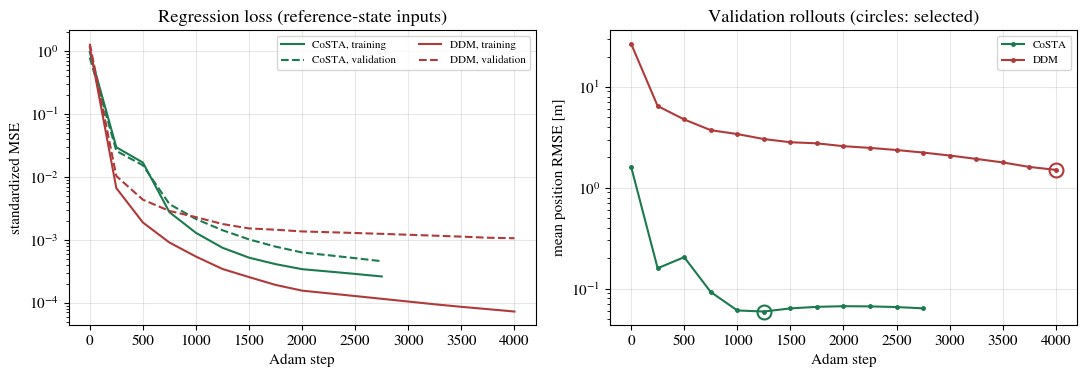

In [8]:
def plot_costa_vessel_training():
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
    for mdl_name, inf, c in [('CoSTA', info_c, 'C2'), ('DDM', info_d, 'C3')]:
        h = inf['hist']
        ax[0].semilogy(h['step'], h['train_mse'], color=c, label=f'{mdl_name}, training')
        ax[0].semilogy(h['step'], h['val_mse'], color=c, ls='--', label=f'{mdl_name}, validation')
        ax[1].semilogy(h['step'], h['val_rollout'], color=c, marker='.', ms=5, label=mdl_name)
        ax[1].plot(inf['best_step'], inf['best_val_rollout'], 'o', mfc='none', mec=c, ms=10, mew=1.5)
    ax[0].set(xlabel='Adam step', ylabel='standardized MSE', title='Regression loss (reference-state inputs)')
    ax[0].legend(fontsize=8, ncol=2)
    ax[1].set(xlabel='Adam step', ylabel='mean position RMSE [m]',
              title='Validation rollouts (circles: selected)')
    ax[1].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_costa_vessel_training, 'costa_vessel_training', FIG)
plt.show()

Left: both regression losses fall. CoSTA's validation loss stays within a factor of about two of its training loss.
The DDM's training loss keeps falling to $7\times10^{-5}$ while its validation loss levels off near $10^{-3}$, so its
fit to the training maneuvers transfers less well to new ones.

Right: the selection metric, the mean position RMSE of the two recursive validation rollouts.

* CoSTA reaches about 6 cm after 1000 steps and then stops improving. The selected checkpoint is step 1250
  (0.059 m), and early stopping ends training at step 2750.
* The DDM starts at 27 m and is still improving when its budget of 4000 steps runs out. Its selected checkpoint is
  the last one, at 1.50 m. A larger budget would probably help the DDM; we keep the declared budget and say so.

The checks at the end of the training cell pass. The numpy forward pass used in rollouts matches the torch
network, evaluation leaves the weights unchanged, and every normalized DDM input on the validation and test
maneuvers is finite. The largest is 9.9 training standard deviations, which comes from the 300 N thrust of an
extrapolation test. With $\alpha=0$, CoSTA reproduces the PBM rollout bit for bit.

## 4. Testing: frozen models, recursive simulation, every role reported separately

All three models now run every maneuver from rest with the recorded controls, feeding back their own states. The
reference is consulted only afterwards, to score. Per maneuver we report, in physical units:

* **position RMSE** over the 30 s, $\sqrt{\tfrac1{N+1}\sum_k\|\boldsymbol{p}_k-\boldsymbol{p}^*_k\|^2}$ in metres (the
  headline metric), and the **final position error** at $t=30$ s;
* **heading error**, wrapped to $(-180^\circ,180^\circ]$, as an RMS and at the final time;
* **velocity RMSE** for $u$, $v$ and $r$ separately (in the results file).

Training rows are reconstructions of maneuvers the networks were fitted on, and validation rows were used to pick
the checkpoint. Only the test rows measure generalization.

In [9]:
def evaluate(models):
    rows = []
    for role in ROLES:
        cases = SPLIT[role]
        sims = {k: rollout(cases, mdl) for k, mdl in models.items()}
        for i, m in enumerate(cases):
            rows.append(dict(role=role, case=name(m), **{k: scores(P[i], CASES[m]['Z']) for k, P in sims.items()}))
    return rows

rows = evaluate({'pbm': None, 'ddm': ddm, 'costa': costa})
ROW = {rw['case']: rw for rw in rows}
print(f"{'role':12s} {'maneuver':18s} | {'position RMSE [m]':^26s} | {'final position error [m]':^26s} | "
      f"{'heading RMS [deg]':^20s}")
print(f"{'':12s} {'':18s} | {'PBM':>8s} {'DDM':>8s} {'CoSTA':>8s} | {'PBM':>8s} {'DDM':>8s} {'CoSTA':>8s} | "
      f"{'PBM':>6s} {'DDM':>6s} {'CoSTA':>6s}")
for rw in rows:
    a, b, c = rw['pbm'], rw['ddm'], rw['costa']
    tag = '  <- reconstruction' if rw['case'] == name(RECON) else ''
    print(f"{rw['role']:12s} {rw['case']:18s} | {a['pos_rmse']:8.3f} {b['pos_rmse']:8.3f} {c['pos_rmse']:8.4f} | "
          f"{a['pos_final']:8.3f} {b['pos_final']:8.3f} {c['pos_final']:8.4f} | "
          f"{a['head_rms_deg']:6.2f} {b['head_rms_deg']:6.2f} {c['head_rms_deg']:6.2f}{tag}")
n_nonfinite = sum(not np.isfinite(rw[k]['pos_rmse']) for rw in rows for k in ('pbm', 'ddm', 'costa'))
print(f'non-finite rollouts: {n_nonfinite}')

role         maneuver           |     position RMSE [m]      |  final position error [m]  |  heading RMS [deg]  
                                |      PBM      DDM    CoSTA |      PBM      DDM    CoSTA |    PBM    DDM  CoSTA
train        TC(120, +30)       |    0.739    0.025   0.0139 |    1.468    0.027   0.0224 |  51.63   0.24   0.51  <- reconstruction
train        TC(120, -30)       |    0.739    0.024   0.0375 |    1.468    0.021   0.0383 |  51.63   0.32   1.09
train        TC(80, +50)        |    0.526    0.017   0.0096 |    0.558    0.021   0.0095 |  80.83   0.50   0.21
train        ZZ(130, ±75, 0.35) |   10.474    0.641   0.2032 |   23.544    0.932   0.2247 |  61.41   1.56   0.67
train        ZZ(90, ±55, 0.5)   |    3.121    0.480   0.1328 |    7.408    0.708   0.2566 |  16.32   1.29   0.47
val          TC(100, +40)       |    0.653    0.124   0.0019 |    1.172    0.184   0.0013 |  63.08  11.04   0.09
val          ZZ(100, ±70, 0.5)  |    3.625    2.883   0.1166 |    8.017    5.

Read the table by role. All numbers are position RMSE over the 30 s unless stated.

* **Training reconstruction.** On the original turning circle `TC(120, +30)` the PBM is off by 0.74 m, the DDM by
  0.025 m and CoSTA by 0.014 m. Both learned models fit their training data. On `TC(120, -30)` the DDM (0.024 m) is
  slightly better than CoSTA (0.038 m).
* **Validation.** CoSTA 0.002 m and 0.12 m; DDM 0.12 m and 2.9 m; PBM 0.65 m and 3.6 m. These cases chose the
  checkpoints, so they are mildly optimistic.
* **Test, interpolation.** On `TC(110, -40)`: PBM 0.69 m, DDM 0.13 m, CoSTA 0.040 m. On the zig-zag
  `ZZ(110, ±65, 0.4)`: PBM 5.8 m, DDM 3.2 m, CoSTA 0.13 m. The heading tells the same story: the RMS heading error on the
  zig-zag is $52^\circ$ for the PBM, $11^\circ$ for the DDM and $0.4^\circ$ for CoSTA.
* **Test, extrapolation.** On `ZZ(160, ±80, 0.35)`: PBM 11.9 m, DDM 24.3 m, CoSTA 0.77 m, with final position errors of
  17.4, 51.6 and 1.7 m. On `TC(300, -25)`: PBM 1.06 m, DDM 3.7 m, CoSTA 0.23 m.

Three observations:

* CoSTA has the lowest position RMSE on all four test maneuvers in this run.
* The DDM beats the PBM on every training, validation and interpolation case, but is **worse than the PBM on both
  extrapolation cases**. Its input includes the control, and the extrapolation controls lie outside the training
  range; it has no physics to fall back on there.
* CoSTA's error grows by a factor of about 6 from the interpolation zig-zag to the extrapolation zig-zag, so it
  also degrades when states leave the training box. It degrades from a much lower starting point, because most of
  the dynamics is carried by the nominal model.

Every rollout stayed finite.

### The original turning circle, as a training reconstruction

Earlier versions of this notebook trained on the turning circle `TC(120, +30)` alone and then showed CoSTA
reproducing it. That maneuver is still in the training set, so its row above is a **reconstruction**: it shows the
fit, not generalization. The figures below use held-out test maneuvers instead.

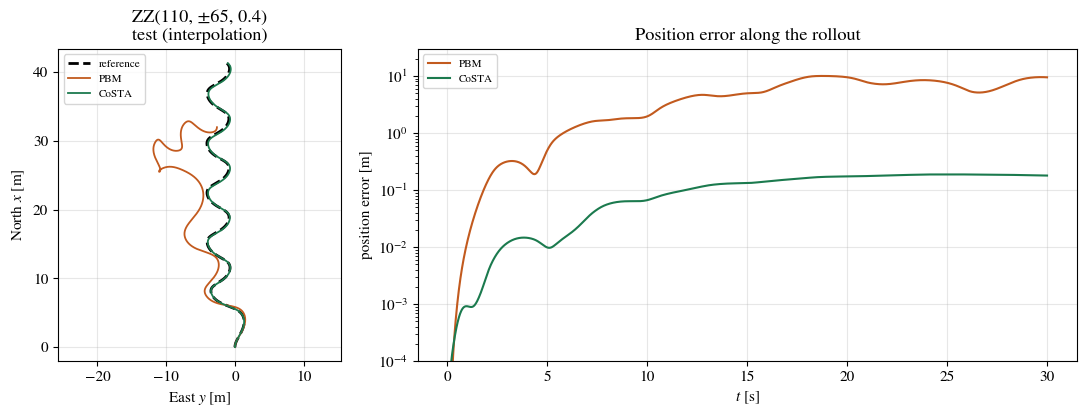

In [10]:
P_int = {k: rollout([SHOW_INTERP], mdl)[0] for k, mdl in [('pbm', None), ('ddm', ddm), ('costa', costa)]}
P_ext = {k: rollout([SHOW_EXTRAP], mdl)[0] for k, mdl in [('pbm', None), ('ddm', ddm), ('costa', costa)]}
Z_int, Z_ext = CASES[SHOW_INTERP]['Z'], CASES[SHOW_EXTRAP]['Z']
pos_err = lambda P, Z: np.hypot(P[:, 0] - Z[:, 0], P[:, 1] - Z[:, 1])
head_err = lambda P, Z: np.degrees(np.abs(np.angle(np.exp(1j*(P[:, 2] - Z[:, 2])))))

def path_and_error(P, Z, case, role, keys):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw=dict(width_ratios=[0.6, 1.4]))
    ax[0].plot(Z[:, 1], Z[:, 0], '--', color=fg(), lw=2, label='reference')
    style = {'pbm': ('C1', 'PBM'), 'ddm': ('C3', 'DDM'), 'costa': ('C2', 'CoSTA')}
    for k in keys:
        ax[0].plot(P[k][:, 1], P[k][:, 0], style[k][0], lw=1.3, label=style[k][1])
        ax[1].semilogy(t_grid[1:], pos_err(P[k], Z)[1:], style[k][0], label=style[k][1])
    ax[0].set_aspect('equal', adjustable='datalim'); ax[0].legend(fontsize=8, loc='upper left')
    ax[1].set_ylim(bottom=1e-4)
    ax[0].set(xlabel='East $y$ [m]', ylabel='North $x$ [m]', title=f'{case}\n{ROLE_LABEL[role]}')
    ax[1].legend(fontsize=8)
    ax[1].set(xlabel='$t$ [s]', ylabel='position error [m]', title='Position error along the rollout')
    plt.tight_layout()

save_dual(lambda: path_and_error(P_int, Z_int, name(SHOW_INTERP), 'test_interp', ['pbm', 'costa']),
          'costa_correction', FIG)
plt.show()

The held-out interpolation zig-zag. Left: the PBM, missing the drag, turns differently from the reference and
loses its heading after the second switch; its path wanders 10 m west. CoSTA follows the dashed reference. Right: the
position error over the rollout. The PBM error reaches 1 m within 5 s and about 10 m by the end. CoSTA's error grows
more slowly and stays below 0.2 m (final 0.18 m), because it is fed its own states throughout and its small errors
do not trigger a different heading history.

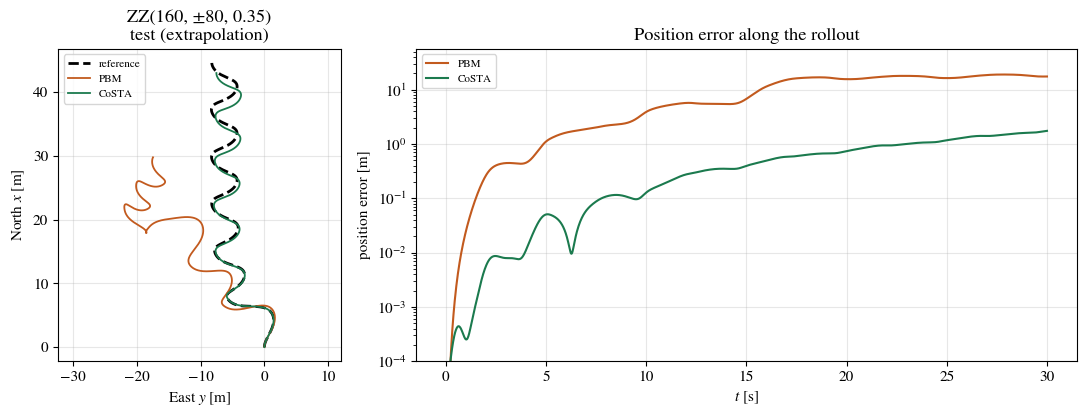

In [11]:
save_dual(lambda: path_and_error(P_ext, Z_ext, name(SHOW_EXTRAP), 'test_extrap', ['pbm', 'costa']),
          'costa_generalization', FIG)
plt.show()

The same view for the extrapolation zig-zag, with 160 N thrust and a $\pm80$ N m yaw moment, both beyond any
training maneuver. The PBM error again reaches 10 m and more. CoSTA stays on the reference path for about half the
run, then drifts slowly; its error grows steadily to 1.7 m at 30 s. The correction transfers, with a clear loss of
accuracy compared with the interpolation case. The next section shows where that loss comes from.

## 5. What was learned: the force on held-out states

The correction is a force in newtons, so it can be compared with the hidden drag directly. We evaluate
$\boldsymbol{f}_{\boldsymbol{\theta}}$ on the **reference** states of the test maneuvers and plot it against $\boldsymbol{d}(\boldsymbol\nu)$,
one panel per component, with the training states in a lighter colour. This is a one-step (reference-state)
diagnostic, not a rollout.

force RMSE on training               states (surge N, sway N, yaw N m): [0.1   0.195 0.146]
force RMSE on test (interpolation)   states (surge N, sway N, yaw N m): [0.139 0.195 0.214]
force RMSE on test (extrapolation)   states (surge N, sway N, yaw N m): [1.469 1.886 0.524]


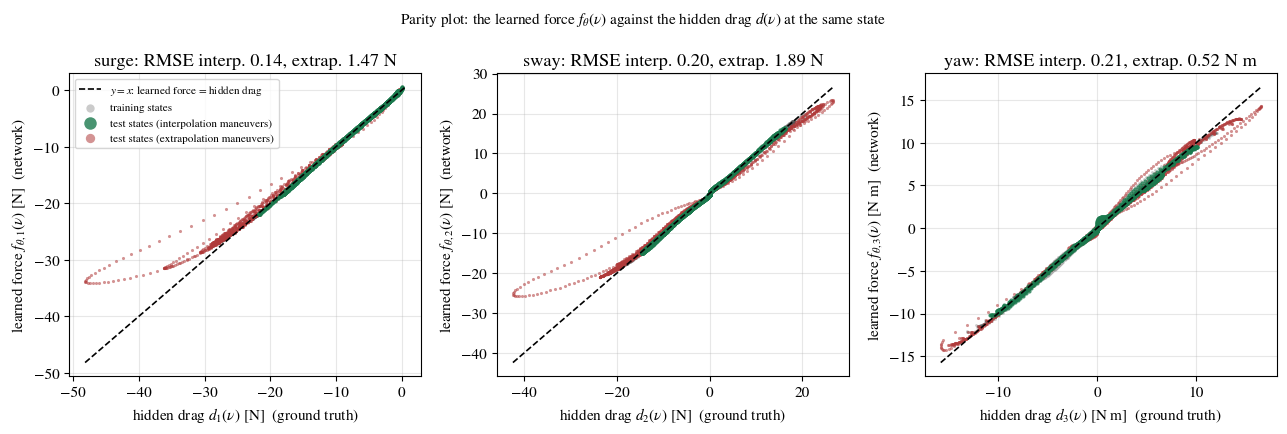

In [12]:
def force_parity(cases):
    nu = np.vstack([CASES[m]['Z'][:, 3:] for m in cases]); return drag(nu), costa(nu)

D_tr, F_tr_hat = force_parity(TRAIN)
D_ti, F_ti_hat = force_parity(TEST_INTERP)
D_te, F_te_hat = force_parity(TEST_EXTRAP)
FORCE_RMSE = {role: [float(v) for v in np.sqrt(np.mean((Fh - Dd)**2, 0))]
              for role, Dd, Fh in [('train', D_tr, F_tr_hat), ('test_interp', D_ti, F_ti_hat),
                                   ('test_extrap', D_te, F_te_hat)]}
for role, v in FORCE_RMSE.items():
    print(f'force RMSE on {ROLE_LABEL[role]:22s} states (surge N, sway N, yaw N m): {np.round(v, 3)}')

def plot_costa_recovery():
    """Parity plot: x = the hidden drag d(nu) the reference used at a state, y = the network's force at the same state."""
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
    comp = ['surge', 'sway', 'yaw']
    for j, lab in enumerate(comp):
        unit = 'N m' if j == 2 else 'N'
        ax[j].scatter(D_tr[:, j], F_tr_hat[:, j], s=4, color=muted(), alpha=0.3, label='training states', zorder=1, lw=0)
        ax[j].scatter(D_te[:, j], F_te_hat[:, j], s=5, color='C3', alpha=0.55, label='test states (extrapolation maneuvers)',
                      zorder=2, lw=0)
        ax[j].scatter(D_ti[:, j], F_ti_hat[:, j], s=9, color='C2', alpha=0.8, label='test states (interpolation maneuvers)',
                      zorder=3, lw=0)
        allv = np.concatenate([D_tr[:, j], D_te[:, j], F_te_hat[:, j], D_ti[:, j]])
        lo, hi = allv.min(), allv.max()
        ax[j].plot([lo, hi], [lo, hi], '--', color=fg(), lw=1.2, zorder=4, label='$y=x$: learned force = hidden drag')
        ax[j].set(xlabel=f'hidden drag $d_{j+1}(\\nu)$ [{unit}]  (ground truth)',
                  ylabel=f'learned force $f_{{\\theta,{j+1}}}(\\nu)$ [{unit}]  (network)',
                  title=f'{lab}: RMSE interp. {FORCE_RMSE["test_interp"][j]:.2f}, extrap. {FORCE_RMSE["test_extrap"][j]:.2f} {unit}')
    h, l = ax[0].get_legend_handles_labels()
    ax[0].legend([h[3], h[0], h[2], h[1]], [l[3], l[0], l[2], l[1]], fontsize=8, markerscale=3, loc='upper left')
    fig.suptitle(r'Parity plot: the learned force $f_\theta(\nu)$ against the hidden drag $d(\nu)$ at the same state',
                 fontsize=11)
    plt.tight_layout()

save_dual(plot_costa_recovery, 'costa_recovery', FIG)
plt.show()

On training states (grey) and interpolation-test states (green) the learned force lies on the diagonal: the force
RMSE is 0.10 to 0.20 N in surge and sway and 0.15 to 0.21 N m in yaw, against drag forces of several newtons. On the
extrapolation-test states (red) the RMSE rises to 1.5 N (surge), 1.9 N (sway) and 0.5 N m (yaw). The red points
leave the diagonal exactly where the drag exceeds anything in the training data: surge drag beyond about $-30$ N
($u$ above the training maximum of 3.0 m/s) and sway drag beyond about $\pm20$ N. Inside the visited region the
network has learned the drag law; outside it, it extrapolates like any function fit and flattens off.

This is a statement about states, not maneuvers. A new maneuver whose states stay inside the visited region is easy
for the correction; a maneuver that pushes the speeds higher is not.

## 6. Scaling the correction: $\alpha$ from 0 to 1

Multiply the learned force by $\alpha$ and rerun the held-out interpolation zig-zag. At $\alpha=0$ the model **is**
the PBM: the same arithmetic, bit for bit, as checked in Section 3. That is an identity. What happens for
$0<\alpha<1$ is an empirical question about this learned force, so we simply measure it.

alpha = 0.0: position RMSE 5.827 m
alpha = 0.1: position RMSE 9.863 m
alpha = 0.2: position RMSE 5.662 m
alpha = 0.3: position RMSE 5.280 m
alpha = 0.4: position RMSE 8.616 m
alpha = 0.5: position RMSE 4.976 m
alpha = 0.6: position RMSE 3.275 m
alpha = 0.7: position RMSE 2.118 m
alpha = 0.8: position RMSE 1.269 m
alpha = 0.9: position RMSE 0.541 m
alpha = 1.0: position RMSE 0.133 m


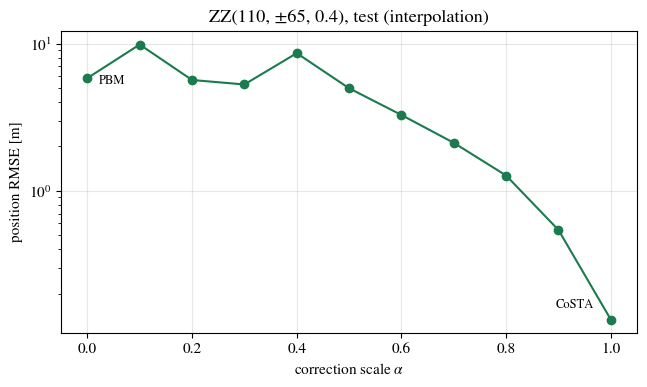

In [13]:
alpha_rmse = [scores(rollout([SHOW_INTERP], costa, a)[0], Z_int)['pos_rmse'] for a in ALPHAS]
assert alpha_rmse[0] == ROW[name(SHOW_INTERP)]['pbm']['pos_rmse']
for a, e in zip(ALPHAS, alpha_rmse):
    print(f'alpha = {a:.1f}: position RMSE {e:.3f} m')

def plot_costa_graceful():
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    ax.semilogy(ALPHAS, alpha_rmse, 'o-', color='C2')
    ax.annotate('PBM', (ALPHAS[0], alpha_rmse[0]), xytext=(8, -4), textcoords='offset points', fontsize=9)
    ax.annotate('CoSTA', (ALPHAS[-1], alpha_rmse[-1]), xytext=(-12, 8), textcoords='offset points',
                ha='right', fontsize=9)
    ax.set(xlabel=r'correction scale $\alpha$', ylabel='position RMSE [m]',
           title=f'{name(SHOW_INTERP)}, test (interpolation)')
    plt.tight_layout()

save_dual(plot_costa_graceful, 'costa_graceful', FIG)
plt.show()

At $\alpha=0$ the position RMSE is 5.83 m, identical to the PBM, as the identity requires. At $\alpha=1$ it is
0.13 m. In between the curve is **not monotonic**: $\alpha=0.1$ gives 9.9 m and $\alpha=0.4$ gives 8.6 m, both worse
than the PBM, before the error falls steadily from $\alpha=0.5$ onwards. A partially corrected model is a different
model. On this directionally unstable hull, with the controls replayed open loop, small changes in the turning
response change when and how far the vessel swings, and the position error is very sensitive to that.

So the precise fallback property is only this: $\alpha=0$ reproduces the nominal model from the same initial state
and inputs. It is not a bound. Scaling the correction does not interpolate the error between the PBM and CoSTA, and
switching the correction off after a rollout has drifted does not undo the drift.

## 7. PBM, DDM and CoSTA side by side

The bars repeat the position RMSE of the table for every maneuver, grouped by role, on a log axis. When a saved
seed sweep exists (Section 9), the error bars show the minimum and maximum over the sweep seeds; the bars themselves
are the seed-0 walkthrough. The second figure follows the extrapolation zig-zag over time.

seed sweep table: loaded from ../data/costa_vessel_results.json


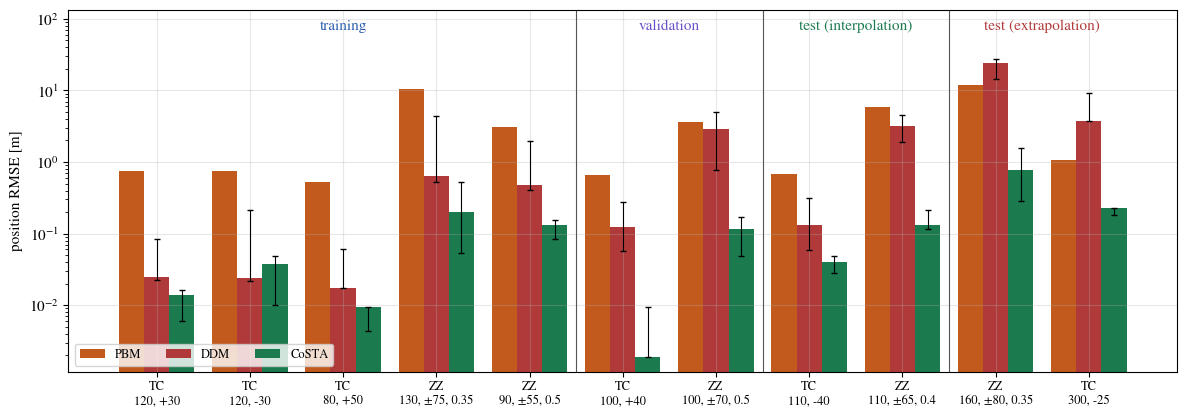

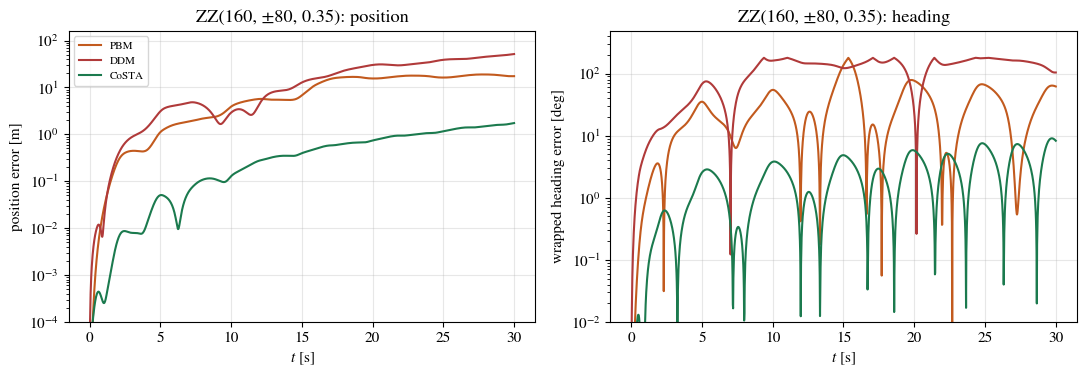

test (interpolation)  TC(110, -40)      : lowest position RMSE CoSTA (PBM/CoSTA =   17.1, DDM/CoSTA =    3.2)
test (interpolation)  ZZ(110, ±65, 0.4) : lowest position RMSE CoSTA (PBM/CoSTA =   43.8, DDM/CoSTA =   24.2)
test (extrapolation)  ZZ(160, ±80, 0.35): lowest position RMSE CoSTA (PBM/CoSTA =   15.6, DDM/CoSTA =   31.6)
test (extrapolation)  TC(300, -25)      : lowest position RMSE CoSTA (PBM/CoSTA =    4.7, DDM/CoSTA =   16.3)


In [14]:
SWEEP = None                     # with RUN_SEED_SWEEP the sweep is computed in Section 9
if not RUN_SEED_SWEEP and os.path.exists(RESULTS_FILE):
    with open(RESULTS_FILE) as fh:
        saved = json.load(fh)
    SWEEP = saved.get('seed_sweep')
    if SWEEP is not None and SWEEP.get('config') != dict(SWEEP_SEEDS=SWEEP_SEEDS, at_defaults=AT_DEFAULTS):
        print('saved seed sweep was made with different settings; not used')
        SWEEP = None
print('seed sweep table:', 'loaded from ' + os.path.relpath(RESULTS_FILE) if SWEEP else 'not available')

def plot_costa_vessel_headtohead():
    fig, ax = plt.subplots(figsize=(12, 4.3))
    order = [(role, name(m)) for role in ROLES for m in SPLIT[role]]
    xb = np.arange(len(order)); w = 0.27
    for j, (k, lab, c) in enumerate([('pbm', 'PBM', 'C1'), ('ddm', 'DDM', 'C3'), ('costa', 'CoSTA', 'C2')]):
        vals = np.array([ROW[cs][k]['pos_rmse'] for _, cs in order])
        yerr = None
        if SWEEP is not None and k != 'pbm':
            lo = np.array([SWEEP['cases'][cs][k]['pos_rmse']['min'] for _, cs in order])
            hi = np.array([SWEEP['cases'][cs][k]['pos_rmse']['max'] for _, cs in order])
            yerr = np.vstack([np.clip(vals - lo, 0, None), np.clip(hi - vals, 0, None)])
        ax.bar(xb + (j - 1)*w, vals, w, color=c, label=lab, yerr=yerr, capsize=2,
               error_kw=dict(ecolor=fg(), lw=0.8))
    ax.set_yscale('log'); ax.set_xticks(xb)
    ax.set_xticklabels([cs[:2] + '\n' + cs[3:-1] for _, cs in order], fontsize=9)
    bounds = np.cumsum([len(SPLIT[r]) for r in ROLES])
    for b in bounds[:-1]:
        ax.axvline(b - 0.5, color=muted(), lw=0.8)
    ymax = ax.get_ylim()[1]
    for role, b0, b1 in zip(ROLES, np.r_[0, bounds[:-1]], bounds):
        ax.text((b0 + b1 - 1)/2, ymax*2.2, ROLE_LABEL[role], ha='center', va='top', fontsize=11,
                color=ROLE_COLOR[role])
    ax.set_ylim(top=ymax*3)
    ax.set_ylabel('position RMSE [m]')
    ax.legend(fontsize=9, ncol=3, loc='lower left')
    plt.tight_layout()

save_dual(plot_costa_vessel_headtohead, 'costa_vessel_headtohead', FIG)
plt.show()

def plot_costa_vessel_headtohead_ts():
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
    for k, lab, c in [('pbm', 'PBM', 'C1'), ('ddm', 'DDM', 'C3'), ('costa', 'CoSTA', 'C2')]:
        ax[0].semilogy(t_grid[1:], pos_err(P_ext[k], Z_ext)[1:], c, label=lab)
        ax[1].semilogy(t_grid[1:], head_err(P_ext[k], Z_ext)[1:], c, label=lab)
    ax[0].set_ylim(bottom=1e-4); ax[1].set_ylim(bottom=1e-2)
    ax[0].set(xlabel='$t$ [s]', ylabel='position error [m]', title=f'{name(SHOW_EXTRAP)}: position')
    ax[1].set(xlabel='$t$ [s]', ylabel='wrapped heading error [deg]', title=f'{name(SHOW_EXTRAP)}: heading')
    ax[0].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_costa_vessel_headtohead_ts, 'costa_vessel_headtohead_ts', FIG)
plt.show()

def ratio_summary():
    out = []
    for role in ['test_interp', 'test_extrap']:
        for m in SPLIT[role]:
            r = ROW[name(m)]; best = min(('PBM', 'DDM', 'CoSTA'), key=lambda k: r[k.lower()]['pos_rmse'])
            out.append(f"{ROLE_LABEL[role]:21s} {name(m):18s}: lowest position RMSE {best:5s} "
                       f"(PBM/CoSTA = {r['pbm']['pos_rmse']/r['costa']['pos_rmse']:6.1f}, "
                       f"DDM/CoSTA = {r['ddm']['pos_rmse']/r['costa']['pos_rmse']:6.1f})")
    return out
print('\n'.join(ratio_summary()))

The bars summarize the table; the black whiskers are the minimum and maximum over the five sweep seeds (Section 9).
The pattern is the one described above:

* On training, validation and interpolation cases both learned models are well below the PBM, and CoSTA is below
  the DDM on every one except the `TC(120, -30)` training reconstruction, where the seed-0 DDM is slightly better and
  the seed ranges overlap.
* On the two extrapolation cases the DDM rises above the PBM, while CoSTA stays one to two orders of magnitude below
  both.

The time series shows how the DDM fails on the extrapolation zig-zag. Its heading error reaches tens of degrees within
the first 5 s and then hundreds, so the vessel it predicts is pointing the wrong way and the position error grows to
50 m. The PBM's heading also breaks away, a little later. CoSTA's heading error stays at a few degrees, growing
slowly through the run.

The printed lines above the figure are generated from the numbers, so they stay correct if the parameters change.

## 8. Noisy measurements: choosing the filter on validation

Real velocity logs are noisy, and differentiating them amplifies the noise. We add Gaussian noise with standard
deviation $0.004$ (m/s or rad/s) to the velocities of the **training and validation** logs. Each maneuver gets its
own noise seed (`NOISE_SEED_BASE + index`), separate from the network seed. The positions and controls stay
exact: we assume accurate position fixes and a known command log.

Before differencing, the velocities are smoothed by a centred moving average, separately within each maneuver,
with no padding at the ends; samples whose window is incomplete or spans a control change are dropped. The window
is chosen from the declared list `WINDOWS` by the **validation** rollout position RMSE. The validation rollouts are
scored against the logged (exact) positions. CoSTA is retrained for each window with the same protocol and seed.
Only then is the chosen window's model run on the test maneuvers.

window   1:  7471 samples, label error RMS [ 7.76 11.22  4.28], validation position RMSE 0.046 m (step 3000)


window  11:  7181 samples, label error RMS [1.09 1.52 0.58], validation position RMSE 0.159 m (step 750)


window  21:  6893 samples, label error RMS [1.65 1.66 0.56], validation position RMSE 0.398 m (step 750)


window  41:  6345 samples, label error RMS [4.99 4.22 1.3 ], validation position RMSE 1.340 m (step 250)


window  81:  5328 samples, label error RMS [13.04 10.07  2.26], validation position RMSE 1.201 m (step 0)
validation chooses window 1


PBM                          TC(110, -40) 0.689 m  ZZ(110, ±65, 0.4) 5.827 m  ZZ(160, ±80, 0.35) 11.944 m  TC(300, -25) 1.063 m
CoSTA, clean data            TC(110, -40) 0.040 m  ZZ(110, ±65, 0.4) 0.133 m  ZZ(160, ±80, 0.35) 0.768 m  TC(300, -25) 0.227 m
CoSTA, noisy data (w = 1)    TC(110, -40) 0.044 m  ZZ(110, ±65, 0.4) 0.098 m  ZZ(160, ±80, 0.35) 0.227 m  TC(300, -25) 0.149 m


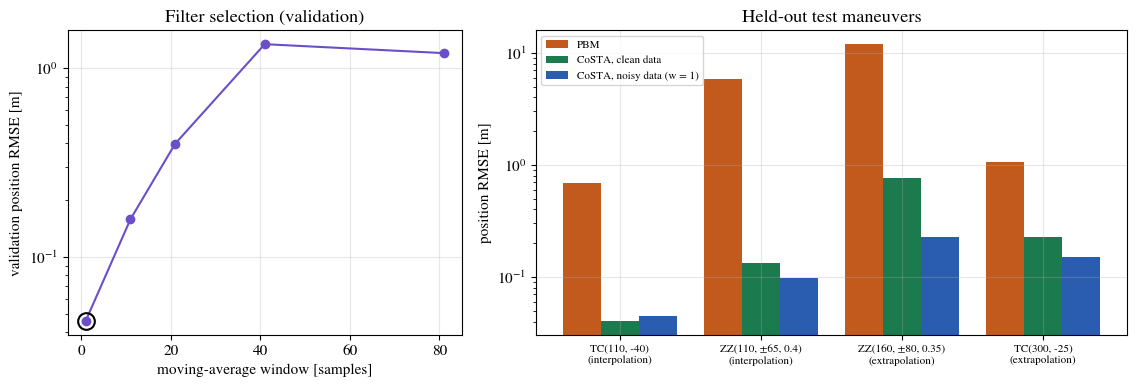

In [15]:
noisy_cases = TRAIN + VAL
OBS = {m: CASES[m]['Z'][:, 3:] + NOISE_STD*np.random.default_rng(NOISE_SEED_BASE + i).standard_normal((N_STEPS + 1, 3))
       for i, m in enumerate(noisy_cases)}
noise_val, noise_models = {}, {}
for w in WINDOWS:
    data_w = dataset(TRAIN, w, OBS)
    lab_err_w = np.sqrt(np.mean((residual_force(*data_w) - drag(data_w[0]))**2, 0))
    mdl, inf = fit('costa', data=data_w)
    noise_val[w], noise_models[w] = inf['best_val_rollout'], mdl
    print(f'window {w:3d}: {len(data_w[0]):5d} samples, label error RMS {np.round(lab_err_w, 2)}, '
          f'validation position RMSE {inf["best_val_rollout"]:.3f} m (step {inf["best_step"]})')
W_STAR = min(WINDOWS, key=lambda w: (noise_val[w], w))
print(f'validation chooses window {W_STAR}')
costa_noisy = noise_models[W_STAR]
TEST_CASES = TEST_INTERP + TEST_EXTRAP
noise_test = {k: [scores(P, CASES[m]['Z'])['pos_rmse'] for P, m in zip(rollout(TEST_CASES, mdl), TEST_CASES)]
              for k, mdl in [('PBM', None), ('CoSTA, clean data', costa), (f'CoSTA, noisy data (w = {W_STAR})', costa_noisy)]}
for k, v in noise_test.items():
    print(f'{k:28s}', '  '.join(f'{name(m)} {e:.3f} m' for m, e in zip(TEST_CASES, v)))

def plot_costa_noise():
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw=dict(width_ratios=[1, 1.5]))
    ax[0].semilogy(WINDOWS, [noise_val[w] for w in WINDOWS], 'o-', color='C4')
    ax[0].plot(W_STAR, noise_val[W_STAR], 'o', ms=12, mfc='none', mec=fg(), mew=1.5)
    ax[0].set(xlabel='moving-average window [samples]', ylabel='validation position RMSE [m]',
              title='Filter selection (validation)')
    xb = np.arange(len(TEST_CASES)); w = 0.27
    for j, ((k, v), c) in enumerate(zip(noise_test.items(), ['C1', 'C2', 'C0'])):
        ax[1].bar(xb + (j - 1)*w, v, w, color=c, label=k)
    ax[1].set_yscale('log'); ax[1].set_xticks(xb)
    ax[1].set_xticklabels([f"{name(m)}\n{ROLE_LABEL[CASES[m]['role']].replace('test ', '')}" for m in TEST_CASES],
                          fontsize=8)
    ax[1].set(ylabel='position RMSE [m]', title='Held-out test maneuvers')
    ax[1].legend(fontsize=8, loc='upper left')
    plt.tight_layout()

save_dual(plot_costa_noise, 'costa_noise', FIG)
plt.show()

**Selection.** Validation picks the window $w=1$, that is, no smoothing at all: its validation position RMSE is
0.046 m, against 0.16 m for $w=11$ and more than 1 m for $w\ge41$. The printed label errors explain why.

* With $w=1$ the labels are very noisy: about 8 N RMS in surge and 11 N in sway, larger than the drag itself. Central
  differencing turns velocity noise of standard deviation $s$ into acceleration noise of about $s/(\sqrt2\,\Delta t)$,
  here 0.14 m/s², which the mass matrix scales to newtons. But this noise has zero mean, and a least-squares fit over
  7471 samples averages it out.
* Smoothing lowers the label noise (1.1 N RMS at $w=11$), but it adds a **bias**: a moving average of the velocity,
  differenced, is the average acceleration over the window, not the acceleration at the sample. That bias is
  systematic and the regression cannot average it away. At $w=81$ (1.6 s) it dominates the label error.

**Test, chosen window only.** On the four held-out test maneuvers the noisy-data CoSTA reaches 0.044, 0.098, 0.23 and
0.15 m, against 0.040, 0.13, 0.77 and 0.23 m for clean-data CoSTA and 0.69 to 11.9 m for the PBM. Noisy data did not
hurt here; on three of the four cases the noisy-data model is even slightly better. Do not read that as "noise helps":
the clean-data model's own seed-to-seed range on the extrapolation zig-zag is 0.29 to 1.59 m, and the noisy-data run
is one more draw. Noise in the inputs can also act as a mild regularizer.

The conclusion depends on the noise level and on how many samples there are. With much stronger noise or a short
log, smoothing would become worth its bias, and validation would pick a larger window.

## 9. Seeds: how much of this is one draw?

One training run is one random initialization. With `RUN_SEED_SWEEP = True` the notebook retrains CoSTA and the
DDM for each seed in `SWEEP_SEEDS` under exactly the same protocol and stores, per maneuver, the median, minimum
and maximum position RMSE and final position error, and the number of non-finite rollouts. Nothing is dropped. The
sweep takes about two minutes, so it is off by default and the saved table is loaded instead.

In [16]:
def spread(vals):
    v = np.array(vals, float); fin = v[np.isfinite(v)]
    return dict(median=float(np.median(v)), min=float(v.min()), max=float(v.max()),
                n_nonfinite=int((~np.isfinite(v)).sum()), values=[float(x) for x in v])

if RUN_SEED_SWEEP:
    t0 = time.time(); runs = {}
    for s in SWEEP_SEEDS:
        mods = {'costa': costa, 'ddm': ddm} if s == SEED else {'costa': fit('costa', seed=s)[0], 'ddm': fit('ddm', seed=s)[0]}
        runs[s] = {rw['case']: rw for rw in evaluate(mods)}
    SWEEP = dict(config=dict(SWEEP_SEEDS=SWEEP_SEEDS, at_defaults=AT_DEFAULTS), cases={})
    for m in all_cases:
        cs = name(m)
        SWEEP['cases'][cs] = dict(role=CASES[m]['role'], **{
            k: {met: spread([runs[s][cs][k][met] for s in SWEEP_SEEDS]) for met in ('pos_rmse', 'pos_final')}
            for k in ('costa', 'ddm')})
    print(f'seed sweep: {time.time()-t0:.0f} s')
    save_dual(plot_costa_vessel_headtohead, 'costa_vessel_headtohead', FIG)   # redraw with error bars
    plt.close('all')

if SWEEP is not None:
    print(f"position RMSE [m] over seeds {SWEEP['config']['SWEEP_SEEDS']}: median [min, max]   (PBM has no seed)")
    print(f"{'role':12s} {'maneuver':18s} {'PBM':>8s} | {'DDM':^28s} | {'CoSTA':^28s}")
    for m in all_cases:
        cs = name(m); d, c = SWEEP['cases'][cs]['ddm']['pos_rmse'], SWEEP['cases'][cs]['costa']['pos_rmse']
        nf = d['n_nonfinite'] + c['n_nonfinite']
        print(f"{CASES[m]['role']:12s} {cs:18s} {ROW[cs]['pbm']['pos_rmse']:8.3f} | "
              f"{d['median']:8.3f} [{d['min']:7.3f}, {d['max']:7.3f}] | "
              f"{c['median']:8.4f} [{c['min']:7.4f}, {c['max']:7.4f}]" + (f'  non-finite: {nf}' if nf else ''))
    for m in TEST_INTERP + TEST_EXTRAP:
        cs = name(m); d, c = SWEEP['cases'][cs]['ddm']['pos_rmse'], SWEEP['cases'][cs]['costa']['pos_rmse']
        rel = ('CoSTA lower for every seed' if c['max'] < d['min'] else
               'DDM lower for every seed' if d['max'] < c['min'] else 'seed ranges overlap')
        print(f"{ROLE_LABEL[CASES[m]['role']]:21s} {cs:18s}: {rel}")
else:
    print('no seed sweep available: set RUN_SEED_SWEEP = True to compute it')

position RMSE [m] over seeds [0, 1, 2, 3, 4]: median [min, max]   (PBM has no seed)
role         maneuver                PBM |             DDM              |            CoSTA            
train        TC(120, +30)          0.739 |    0.033 [  0.022,   0.084] |   0.0109 [ 0.0060,  0.0162]
train        TC(120, -30)          0.739 |    0.122 [  0.022,   0.212] |   0.0276 [ 0.0100,  0.0482]
train        TC(80, +50)           0.526 |    0.040 [  0.017,   0.060] |   0.0055 [ 0.0043,  0.0096]
train        ZZ(130, ±75, 0.35)   10.474 |    3.227 [  0.532,   4.350] |   0.0853 [ 0.0542,  0.5187]
train        ZZ(90, ±55, 0.5)      3.121 |    0.831 [  0.403,   1.982] |   0.1328 [ 0.0845,  0.1549]
val          TC(100, +40)          0.653 |    0.124 [  0.058,   0.281] |   0.0085 [ 0.0019,  0.0093]
val          ZZ(100, ±70, 0.5)     3.625 |    2.883 [  0.783,   5.019] |   0.1329 [ 0.0492,  0.1722]
test_interp  TC(110, -40)          0.689 |    0.108 [  0.060,   0.312] |   0.0404 [ 0.0277,  0.0489]
test_

The table repeats the comparison for five initialization seeds. PBM has no trained parameters and no spread. On the
test maneuvers:

* **CoSTA**: median position RMSE 0.040 m and 0.12 m on the interpolation tests, and 0.35 m and 0.21 m on the
  extrapolation tests. The spread is narrow except on the extrapolation zig-zag, where it runs from 0.29 m to 1.59 m.
  The seed-0 walkthrough (0.77 m there) is one of the worse draws.
* **DDM**: medians 0.11 m and 3.2 m on the interpolation tests, 20 m and 5.3 m on the extrapolation tests, with wider
  spreads (for example 1.9 to 4.5 m on the interpolation zig-zag).
* On every test maneuver the CoSTA range lies entirely below the DDM range. On the training reconstructions the
  ranges overlap.
* No rollout became non-finite for any seed.

These conclusions cover the maneuvers tested here, one hull, one hidden drag law and one set of budgets.

In [17]:
results = dict(
    config={k: globals()[k] for k in DEFAULTS} | dict(RECON=RECON, SHOW_INTERP=SHOW_INTERP, SHOW_EXTRAP=SHOW_EXTRAP,
                                                       ALPHAS=ALPHAS, SWEEP_SEEDS=SWEEP_SEEDS),
    manifest=MANIFEST, coverage=COVERAGE,
    training_box=dict(lo=BOX_LO.tolist(), hi=BOX_HI.tolist()),
    selected=dict(costa=dict(best_step=info_c['best_step'], stopped_at=info_c['stopped_at'],
                             best_val_pos_rmse=info_c['best_val_rollout']),
                  ddm=dict(best_step=info_d['best_step'], stopped_at=info_d['stopped_at'],
                           best_val_pos_rmse=info_d['best_val_rollout'])),
    metrics=rows, force_rmse_on_reference_states=FORCE_RMSE,
    alpha_sweep=dict(case=name(SHOW_INTERP), alphas=ALPHAS, pos_rmse=alpha_rmse),
    noise=dict(std=NOISE_STD, windows=WINDOWS, val_pos_rmse={str(w): noise_val[w] for w in WINDOWS},
               chosen_window=W_STAR, test_pos_rmse={k: dict(zip([name(m) for m in TEST_CASES], v))
                                                    for k, v in noise_test.items()}),
    seed_sweep=SWEEP)
with open(RESULTS_FILE, 'w') as fh:
    json.dump(results, fh, indent=1)
print('saved', os.path.relpath(RESULTS_FILE))
print(f'total run time {time.time() - T_START:.0f} s')

saved ../data/costa_vessel_results.json
total run time 80 s


**Takeaways.**

* CoSTA learns the force the nominal model is missing. Labels come from each maneuver's own velocities, recorded
  controls and the nominal operator; predictions use only the model's own current velocity.
* Training maneuvers fit the networks, validation maneuvers choose the checkpoint (and the noise filter), and the
  frozen models are tested on held-out maneuvers with replayed controls. Training reconstructions, validation,
  interpolation tests and extrapolation tests are reported separately.
* On held-out maneuvers whose states lie inside the training box, CoSTA cuts the PBM's position RMSE by factors of
  about 17 and 44. Where the states leave the box it still helps (factors of about 5 and 16 in the walkthrough), but
  less, and the force parity plot shows why.
* The DDM, given the same data, the same integrator and a larger budget, beats the PBM inside the training range and
  is worse than the PBM outside it. The difference between the two learned models is the physics prior.
* $\alpha=0$ reproduces the PBM exactly. That is the only guarantee; intermediate $\alpha$ was worse than the PBM
  here.
* $\boldsymbol{f}_{\boldsymbol{\theta}}(\boldsymbol\nu)$ is a state-only function because the synthetic drag is. Forces that depend on
  time, position or heading need those inputs.

Because $\boldsymbol{f}_{\boldsymbol{\theta}}$ is a force in physical units that matches $\boldsymbol{d}(\boldsymbol\nu)$ where data exist,
the natural next step is to ask for its formula: fitting a sparse symbolic model to the learned force (or directly to
the residual labels) is equation discovery, the subject of Module 21.